#Aproximação de função utilizando a rede MLP

Realiza a aproximação da onda senoidal utilizando a rede MLP

##Etapa 01
Importar as bibliotecas de aprendizado de máquina e computação científica.

In [8]:
#Bibliotecas de aprendizado de máquina
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense

#Bibliotecas de computação científica
import numpy as np
import matplotlib.pyplot as plt

##Etapa 02
Criar a base de dados sintética.

In [9]:
NUM_SAMPLES = 1000

#Conjunto de treinamento
x_train = np.random.uniform(0, 1, NUM_SAMPLES)
x_train = np.sort(x_train, axis=0)
y_train = np.sin(2 * np.pi * x_train)

#Conjunto de validação
x_test = np.random.uniform(0, 1, int(NUM_SAMPLES/3))
x_test = np.sort(x_test, axis=0)
y_test = np.sin(2 * np.pi * x_test)

##Etapa 03
Conhecer a dimensão dos conjuntos de treinamento e validação.

In [10]:
print('x_train', x_train.shape)
print('y_train', y_train.shape)
print('x_test', x_test.shape)
print('y_test', y_test.shape)

x_train (1000,)
y_train (1000,)
x_test (333,)
y_test (333,)


##Etapa 04
Projetando a rede neural MLP utilizando o Keras.

In [11]:
keras.backend.clear_session()
model = Sequential()
model.add(Dense(8, input_dim = 1, activation='relu')) #sigmoid, relu, gelu, elu:  https://keras.io/api/layers/activations
model.add(Dense(1, activation='linear'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

##Etapa 05
Compilar o modelo.

Optimizer: As opções são encontradas em https://keras.io/api/optimizers/

Loss: As opções são encontradas em https://keras.io/api/losses/

Metrics: As opções são encontradas em https://keras.io/api/metrics/

In [12]:
# Compilação para problema de regressão (MSE e MAE)
otimizador = keras.optimizers.Adam(learning_rate=0.001)
model.compile(optimizer=otimizador,
              loss='mse',
              metrics=['mae'])


##Etapa 06
Treinar o modelo e realizar a validação.

###Critério de parada com controle da função de custo.

Parâmetros:
- monitor: variável monitorada.
- patience: número de épocas aguardadas sem melhoria antes de interromper.
- min_delta=: considera melhoria apenas quando a variável monitorada supera esse valor.
- restore_best_weights=True: recupera os pesos da época com menor erro de validação.

In [13]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    min_delta=1e-4,
    restore_best_weights=True
)

Epoch 1/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5788 - mae: 0.6902 - val_loss: 0.5894 - val_mae: 0.7064
Epoch 2/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5462 - mae: 0.6708 - val_loss: 0.5706 - val_mae: 0.6938
Epoch 3/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5241 - mae: 0.6559 - val_loss: 0.5544 - val_mae: 0.6812
Epoch 4/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5045 - mae: 0.6410 - val_loss: 0.5368 - val_mae: 0.6672
Epoch 5/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4843 - mae: 0.6253 - val_loss: 0.5172 - val_mae: 0.6513
Epoch 6/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4625 - mae: 0.6082 - val_loss: 0.4944 - val_mae: 0.6332
Epoch 7/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4388 - mae: 0.5903 - val_loss: 0.4683 - val_mae: 0.6131
Epoch 8/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4135 - mae: 0.5706 - val_loss: 0.4424 - val_mae: 0.5936
Epoch 9/200
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.390

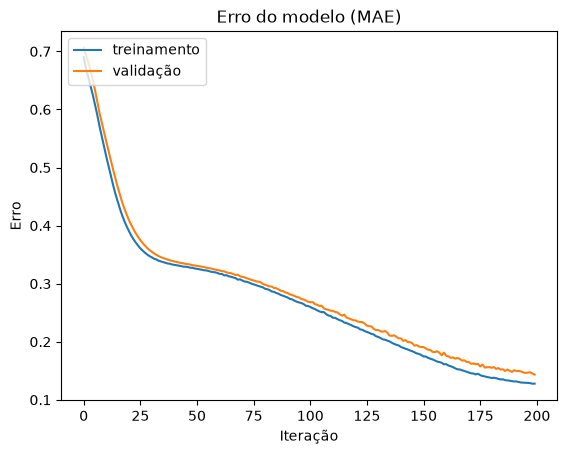

In [14]:
history = model.fit(x_train, y_train, epochs=200, batch_size=16, validation_data=(x_test, y_test), callbacks=[early_stop])
plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Erro do modelo (MAE)')
plt.ylabel('Erro')
plt.xlabel('Iteração')
plt.legend(['treinamento', 'validação'], loc='upper left')
plt.show()


##Etapa 07
Realizar algumas predições.

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


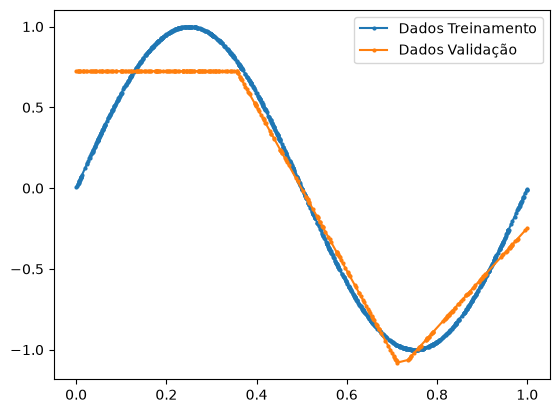

In [15]:
y_pred = model.predict(x_test)

plt.plot(x_train, y_train, '-o', label='Dados Treinamento', markersize=2)
plt.plot(x_test, y_pred, '-o', label='Dados Validação', markersize=2)
plt.legend()
plt.show()


In [16]:
loss, metrica = model.evaluate(x_test, y_test)
print('Loss:', loss)
print('Metrica (MAE):', metrica)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0407 - mae: 0.1453 
Loss: 0.04074424132704735
Metrica (MAE): 0.1453145295381546
